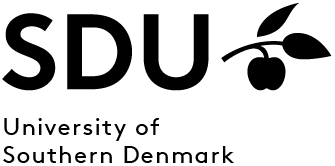
<br><br><br>
<p style="color: #789D4A;font-family: courier;font-size: 160%;text-align:center;">Optimization and Image Processing (E26)</p> 

<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Dr Till Leissner, Associate Professor</p> 
<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Mads Clausen Institute, University of Southern Denmark</p> 

# Week 06 — Problem 2: Image-processing capstone



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, filters, morphology, measure

In [ ]:
image = data.coins()

fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(image, cmap="gray")
ax.set_title("Input image")
ax.axis("off")
plt.show()

## 1. Inspect and plan

Before writing code, discuss with a neighbour:

- What makes segmentation difficult in this image?
- Which operations from earlier weeks might help?
- What would count as an "object" in your analysis?


YOUR PLAN:


## 2. Smooth and threshold

Create:

- `smoothed`: a gently filtered version of the image,
- `threshold`: a threshold value,
- `binary`: a binary mask of likely coin pixels.

You may use a Gaussian filter and Otsu thresholding as a starting point.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

## 3. Clean the mask

Use one or more morphological operations to remove obvious small artefacts.

Store the result in `cleaned`.

You should be able to explain why you chose the operation(s).

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
assert cleaned.shape == image.shape
assert cleaned.dtype == bool

## 4. Label and measure

Label the connected objects using 8-connectivity.

Then compute at least:

- area,
- centroid,
- eccentricity.

Store:

- `labels` for the labelled image,
- `regions` for the list returned by `regionprops`.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
areas = np.array([r.area for r in regions], dtype=float)
eccentricities = np.array([r.eccentricity for r in regions], dtype=float)
centroids = np.array([r.centroid for r in regions]) if regions else np.empty((0, 2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(cleaned, cmap="gray")
axes[1].set_title("Binary mask")

axes[2].imshow(image, cmap="gray")
if len(centroids):
    axes[2].plot(centroids[:, 1], centroids[:, 0], marker="+", linestyle="none")
axes[2].set_title(f"Detected regions: {len(regions)}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.hist(areas, bins=10)
ax.set_xlabel("Region area [pixels]")
ax.set_ylabel("Count")
ax.set_title("Distribution of measured region areas")
plt.show()

## 5. Evaluate your own result

Answer briefly:

1. Which detected regions are likely not individual coins?
2. Which processing step contributes the largest uncertainty?
3. Would the measured pixel area be a reliable physical area? Why or why not?
4. Name one method that could improve the separation of touching objects.

YOUR EVALUATION


## 6. Modify your workflow

- change the smoothing strength,
- change the thresholding method,
- change the connectivity,
- change the minimum object size.

Explain how the final quantitative result changes.